In [4]:
import pandas as pd
import numpy as np
import sklearn

print("Ready!")

Ready!


In [5]:
import pandas as pd

df = pd.read_csv(
    "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset shape: (7043, 21)

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
Paperless

In [6]:
import pandas as pd

df = pd.read_csv(
    "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
# 1. Calculate the overall churn rate
churn_count = (df["Churn"] == "Yes").sum()
total_customers = len(df)

churn_rate = (churn_count / total_customers) * 100

print(f"Total customers: {total_customers}")
print(f"Customers who churned: {churn_count}")
print(f"Overall churn rate: {churn_rate:.2f}%")

# 2. Check for blank values in TotalCharges
df["TotalCharges"] = df["TotalCharges"].replace(
    r"^\s*$", pd.NA, regex=True
)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("\nMissing TotalCharges:", df["TotalCharges"].isna().sum())

Total customers: 7043
Customers who churned: 1869
Overall churn rate: 26.54%

Missing TotalCharges: 11


In [8]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


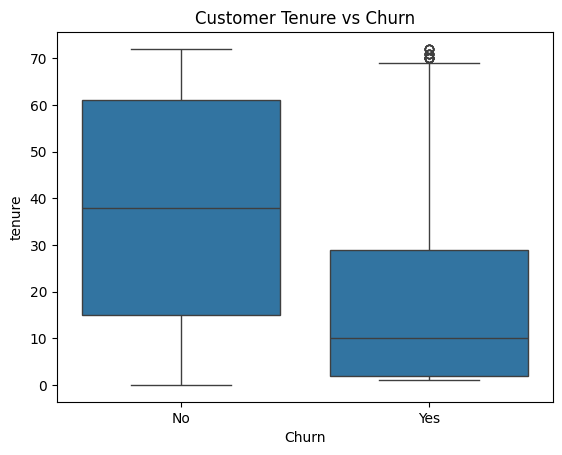

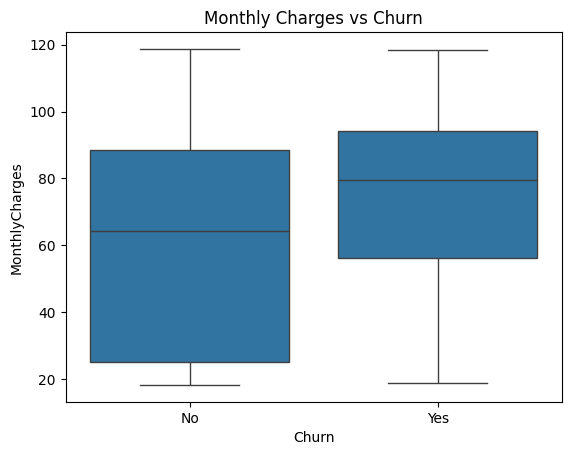

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compare tenure for customers who stayed and left
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure vs Churn")
plt.show()

# Compare monthly charges for customers who stayed and left
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

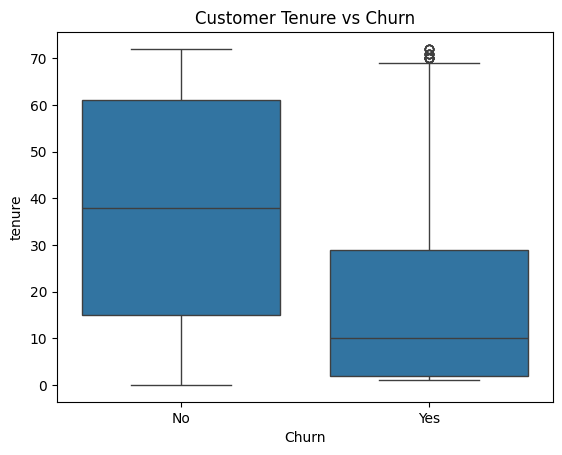

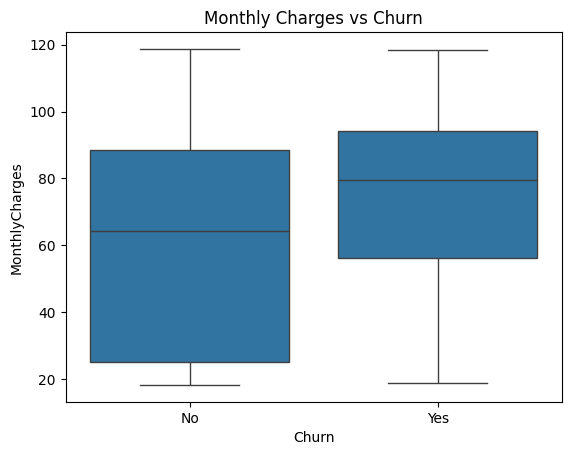

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compare tenure for customers who stayed and left
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure vs Churn")
plt.show()

# Compare monthly charges for customers who stayed and left
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

In [11]:
# Inspect rows with missing TotalCharges
missing_rows = df[df["TotalCharges"].isna()]

display(
    missing_rows[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

print("Number of missing rows:", len(missing_rows))
print("Tenure values:", missing_rows["tenure"].unique())

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Number of missing rows: 11
Tenure values: [0]


In [12]:
# Replace missing TotalCharges with 0 for zero-tenure customers
df.loc[df["tenure"] == 0, "TotalCharges"] = (
    df.loc[df["tenure"] == 0, "TotalCharges"].fillna(0)
)

# Verify missing values are handled
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("Dataset shape:", df.shape)

# Remove customerID because it is only an identifier
df = df.drop(columns=["customerID"])

print("Columns remaining:", len(df.columns))
display(df.head())

Missing TotalCharges: 0
Dataset shape: (7043, 21)
Columns remaining: 20


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [13]:
# Separate the target from the input features
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [14]:
from sklearn.model_selection import train_test_split

# Split the data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object"]).columns

print("Numerical features:", list(numeric_features))
print("Categorical features:", len(categorical_features))

# Prepare numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the model pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("\nLogistic Regression model trained successfully!")

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: 15

Logistic Regression model trained successfully!


In [16]:
# Predict churn on unseen test data
y_pred = logistic_model.predict(X_test)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Stayed", "Churned"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Results
---------------------------
Accuracy:  0.8055
Precision: 0.6572
Recall:    0.5588
F1-score:  0.6040

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[926 109]
 [165 209]]


In [17]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

# Predict on the test data
tree_pred = decision_tree_model.predict(X_test)

# Evaluate
print("Decision Tree Results")
print("---------------------")
print(f"Accuracy:  {accuracy_score(y_test, tree_pred):.4f}")
print(f"Precision: {precision_score(y_test, tree_pred):.4f}")
print(f"Recall:    {recall_score(y_test, tree_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, tree_pred):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    tree_pred,
    target_names=["Stayed", "Churned"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, tree_pred))

Decision Tree Results
---------------------
Accuracy:  0.7395
Precision: 0.5060
Recall:    0.7914
F1-score:  0.6173

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.91      0.72      0.80      1035
     Churned       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Confusion Matrix:
[[746 289]
 [ 78 296]]


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,Decision Tree,0.7395,0.5060,0.7914,0.6173


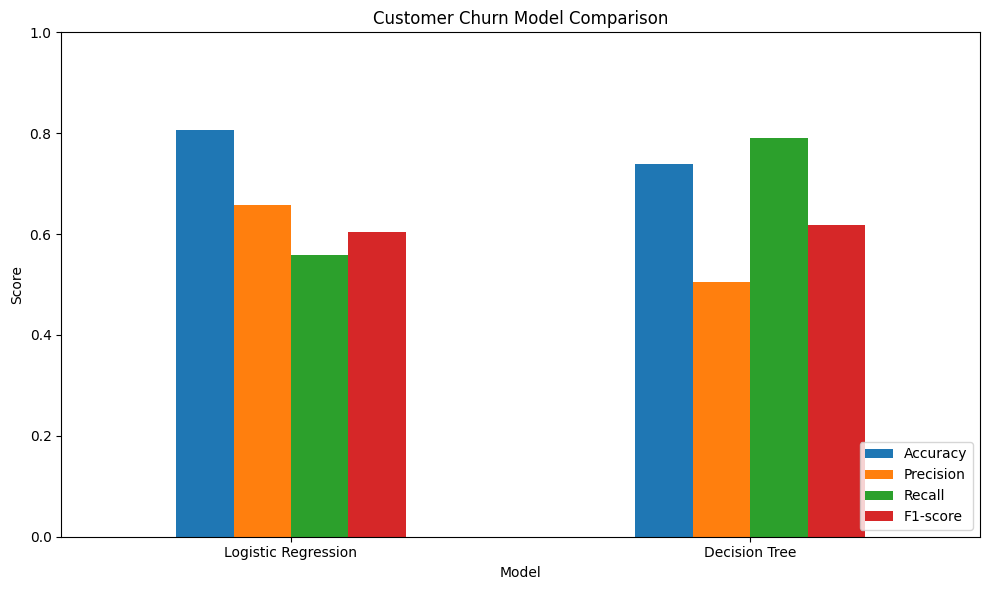

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tree_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, tree_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, tree_pred)
    ],
    "F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, tree_pred)
    ]
})

display(comparison.round(4))

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("Customer Churn Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [19]:
# Create a copy of the cleaned dataset for business analysis
analysis_df = df.copy()

# Convert target back to readable labels for analysis
analysis_df["Churn"] = analysis_df["Churn"].map({
    0: "No",
    1: "Yes"
})

# Calculate churn rates by customer group
def churn_summary(column):
    summary = (
        analysis_df.groupby(column, observed=True)["Churn"]
        .apply(lambda values: (values == "Yes").mean() * 100)
        .sort_values(ascending=False)
        .round(2)
    )
    return summary.rename("Churn Rate (%)").to_frame()

print("Churn rate by Contract:")
display(churn_summary("Contract"))

print("Churn rate by Internet Service:")
display(churn_summary("InternetService"))

print("Churn rate by Payment Method:")
display(churn_summary("PaymentMethod"))

Churn rate by Contract:


,Churn Rate (%)
Contract,
Month-to-month,0.0
One year,0.0
Two year,0.0


Churn rate by Internet Service:


,Churn Rate (%)
InternetService,
DSL,0.0
Fiber optic,0.0
No,0.0


Churn rate by Payment Method:


,Churn Rate (%)
PaymentMethod,
Bank transfer (automatic),0.0
Credit card (automatic),0.0
Electronic check,0.0
Mailed check,0.0


In [20]:
# Check the actual labels in the dataset
print("Churn values:", df["Churn"].unique())

# Calculate the percentage of customers who churned in each group
def churn_summary(column):
    summary = (
        df.groupby(column, observed=True)["Churn"]
        .apply(lambda values: (values == "Yes").mean() * 100)
        .sort_values(ascending=False)
        .round(2)
    )
    return summary.rename("Churn Rate (%)").to_frame()

print("\nChurn rate by Contract:")
display(churn_summary("Contract"))

print("Churn rate by Internet Service:")
display(churn_summary("InternetService"))

print("Churn rate by Payment Method:")
display(churn_summary("PaymentMethod"))

Churn values: ['No' 'Yes']

Churn rate by Contract:


,Churn Rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


Churn rate by Internet Service:


,Churn Rate (%)
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40


Churn rate by Payment Method:


,Churn Rate (%)
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


In [21]:
# Predict churn probabilities on the test set
churn_probabilities = decision_tree_model.predict_proba(X_test)[:, 1]

# Build a risk table
risk_table = X_test.copy()
risk_table["Actual_Churn"] = y_test.values
risk_table["Predicted_Churn_Probability"] = churn_probabilities
risk_table["Predicted_Churn"] = tree_pred

# Display the 10 highest-risk customers
high_risk_customers = risk_table.sort_values(
    "Predicted_Churn_Probability",
    ascending=False
).head(10)

display(
    high_risk_customers[
        [
            "tenure",
            "Contract",
            "MonthlyCharges",
            "Predicted_Churn_Probability",
            "Predicted_Churn"
        ]
    ].round(3)
)

,tenure,Contract,MonthlyCharges,Predicted_Churn_Probability,Predicted_Churn
3682,1,Month-to-month,69.10,1.000,1
2927,1,Month-to-month,69.90,1.000,1
1739,1,Month-to-month,69.90,1.000,1
2517,1,Month-to-month,69.50,1.000,1
1731,1,Month-to-month,69.60,1.000,1
4556,2,Month-to-month,67.75,1.000,1
809,1,Month-to-month,69.55,1.000,1
2900,1,Month-to-month,69.25,1.000,1
3906,1,Month-to-month,78.80,0.963,1
642,1,Month-to-month,89.55,0.963,1


## Business Insights and Retention Recommendations

### Key Findings

1. **Contract type:** Month-to-month customers have a churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.
2. **Customer tenure:** The exploratory boxplot shows that churned customers generally have shorter tenures than customers who stay.
3. **Internet service:** Fiber-optic customers have a churn rate of 41.89%, compared with 18.96% for DSL customers.
4. **Payment method:** Electronic-check customers have a churn rate of 45.29%, the highest among the payment methods examined.
5. **Model comparison:** Logistic Regression achieved 80.55% accuracy, while the Decision Tree achieved 73.95%. The Decision Tree had higher churn recall (79.14% versus 55.88%), making it useful to consider when identifying more potential churners is a priority.

### Recommended Retention Strategies

1. **Early customer engagement:** Prioritize onboarding and satisfaction check-ins for new customers, especially those on month-to-month contracts.
2. **Contract retention offers:** Test suitable discounts or plan benefits that encourage customers to consider longer-term contracts.
3. **Targeted service and payment reviews:** Investigate satisfaction among fiber-optic and electronic-check customers before designing targeted support or retention campaigns.

### Limitations

This project uses a public telecom dataset and a single train/test split. The observed relationships do not establish causation. The model has not been tested in a live business environment, and its predicted probabilities should be validated before operational use.